In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pymc as pm
import pymc_bart as pmb
import numpy as np
print(f"PyMC Version: {pm.__version__}")
print(f"PyMC-BART Version: {pmb.__version__}")
print(f"Numpy Version: {np.__version__}")

PyMC Version: 6.0.0
PyMC-BART Version: 0.12.0
Numpy Version: 2.0.2


In [3]:
import os
import psutil
import gc

def check_local_mac_ram():
    """
    Captures the exact resident memory footprint of your Python script
    and all parallel MCMC chain workers running locally on macOS.
    """
    try:
        main_pid = os.getpid()
        main_process = psutil.Process(main_pid)
        
        # Grab memory of the main script/notebook process
        total_rss = main_process.memory_info().rss
        
        # Find all parallel worker processes spawned for the chains
        workers = main_process.children(recursive=True)
        
        for worker in workers:
            try:
                # RSS is the actual physical memory occupied in RAM
                total_rss += worker.memory_info().rss
            except (psutil.NoSuchProcess, psutil.AccessDenied):
                # Handles workers shutting down or cycling mid-check
                continue
                
        print(f"Total Local RAM Usage: {total_rss / (1024**3):.2f} GB")
        return None
        
    except Exception as e:
        print(f"Error checking local macOS memory: {e}")
        return None

check_local_mac_ram()

def check_ram(label="Current"):
    # Get the OS-level memory footprint of this specific Jupyter kernel
    process = psutil.Process(os.getpid())
    mem_mb = process.memory_info().rss / (1024 * 1024)
    print(f"[{label}] RAM Usage: {mem_mb:,.2f} MB")

# Check the baseline with all_trees still sitting in memory
check_ram("BEFORE NUKE")

Total Local RAM Usage: 0.25 GB
[BEFORE NUKE] RAM Usage: 259.56 MB


In [4]:
import warnings
# Suppress PyTensor FutureWarnings
warnings.filterwarnings("ignore", module="pytensor")
# Suppress ArviZ MigrationWarnings
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")

In [5]:
from importlib import reload
from bart_survival import surv_bart as sb
from bart_survival import simulation
import numpy as np
import time


In [6]:
rng = np.random.default_rng(1)
x_mat = simulation.get_x_matrix(
    N=5000,
    x_vars=1,
    VAR_CLASS=[2],
    VAR_PROB=[.5],
    rng = rng
)
event_dict, sv_true, sv_scale_true = simulation.simulate_survival(
    x_mat = x_mat,
    scale_f = "np.exp(2 + .6*x_mat[:,0])",
    shape_f = "1",
    eos = 20,
    cens_scale=None,
    time_scale = 1,
    true_only=False,
    rng = rng
)
# prepare data
# t_scale = sb.get_time_transform(event_dict["t_event"], time_scale = 5)
# y_sk = sb.get_y_sklearn(event_dict["status"], t_scale)
trn = sb.get_surv_pre_train(
    y_status=event_dict["status"],
    y_time=event_dict["t_event"],
    x = x_mat, 
    weight=None,
    time_scale = 1
    )
post_test = sb.get_posterior_test(
    y_status=event_dict["status"],
    y_time=event_dict["t_event"],
    x = x_mat,
    time_scale = 1)

SPLIT_RULES =  [
    "pmb.ContinuousSplitRule()", # time
    # "pmb.OneHotSplitRule", # ccsr_ind_p2
    "pmb.ContinuousSplitRule()", # ccsr_ind_p2
]
model_dict = {"trees": 20,
    "split_rules": SPLIT_RULES,
    "num_nodes":15  # 2^node_depth -1
}
sampler_dict = {
            "draws": 150,
            "tune": 200,
            "cores": 8,
            "chains": 8,
            "compute_convergence_checks": False
        }

BSM = sb.BartSurvModel(model_config=model_dict, sampler_config=sampler_dict)
print(trn["y"].shape)

check_ram()
check_local_mac_ram()

mean shape 1.0
mean scale 10.40574314838353
mean time draws 10.219716172599194
(44593, 1)
[Current] RAM Usage: 265.27 MB
Total Local RAM Usage: 0.26 GB


In [22]:
BSM.custom_step.prior_prob_leaf_node[:5]

[0, 0.050000000000000044, 0.7625, 0.8944444444444445, 0.940625]

In [14]:
start = time.perf_counter()
BSM.fit(
    y =  trn["y"],
    X = trn["x"],
    weights=trn["w"],
    coords = trn["coord"],
    random_seed=5
)

end = time.perf_counter()
print(f'TIME: {end - start:0.4f}')

check_ram()
# post1 = BSM.sample_posterior_predictive(X_pred=post_test["post_x"], coords=post_test["coords"])
# sv_prob = sb.get_sv_prob(post1)


check_local_mac_ram()

Multiprocess sampling (4 chains in 4 jobs)
FastSurvMHBART: [trees]


Output()

Sampling 4 chains for 200 tune and 150 draw iterations (800 + 600 draws total) took 4 seconds.


TIME: 6.1245
[Current] RAM Usage: 468.20 MB
Total Local RAM Usage: 0.48 GB


In [9]:
post2 = BSM.predict_posterior(X_pred=post_test["post_x"], coords=post_test["coords"])
sv_prob2 = sb.get_sv_prob(post2)

In [12]:
check_local_mac_ram()

Total Local RAM Usage: 1.23 GB


In [13]:
# pdp
pdp1 = sb.get_pdp(x_mat, var_col = [0], values = [[0,1]], sample_n = None)
pdp_tst = sb.get_posterior_test(
    y_status=event_dict["status"], 
    y_time=event_dict["t_event"],
    x = pdp1[0])
pdp_post = BSM.predict_posterior(pdp_tst["post_x"], pdp_tst["coords"])



: 

In [ ]:
# sv_prob = sb.get_sv_prob(pdp_post)
# msk_1 = pdp1[1]["coord"] == 1
# HR = (sv_prob["prob"][:,msk_1,:].mean(1) / sv_prob["prob"][:,~msk_1,:].mean(1)).mean(0)
# HR_QT = np.quantile((sv_prob["prob"][:,msk_1,:].mean(1) / sv_prob["prob"][:,~msk_1,:].mean(1)),[0.025,0.975])


(array([ 1.,  1.,  0.,  1.,  2.,  0.,  1.,  1.,  1.,  2.,  2.,  5.,  7.,
         4.,  6., 11., 18., 21., 10., 23., 33., 42., 31., 35., 42., 57.,
        41., 46., 61., 40., 49., 49., 45., 51., 55., 40., 33., 41., 34.,
        25., 33., 29., 17., 20.,  7., 13., 12., 16., 14.,  9.,  7., 12.,
         3.,  6.,  7.,  4.,  2.,  2.,  3.,  1.,  0.,  0.,  2.,  1.,  1.,
         3.,  1.,  0.,  0.,  1.,  0.,  0.,  0.,  1.,  2.,  1.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([0.47323617, 0.47755852, 0.48188088, 0.48620323, 0.49052558,
        0.49484794, 0.49917029, 0.50349264, 0.507815  , 0.51213735,
        0.5164597 , 0.52078205, 0.52510441, 0.52942676, 0.53374911,
        0.53807147, 0.54239382, 0.54671617, 0.55103853, 0.55536088,
        0.55968323, 0.56400559, 0.56832794, 0.57265029, 0.57697265,
        0.581295  , 0.58561735, 0.5899397 , 0.59426206, 0.59858441,
        0.60290676, 0.6072

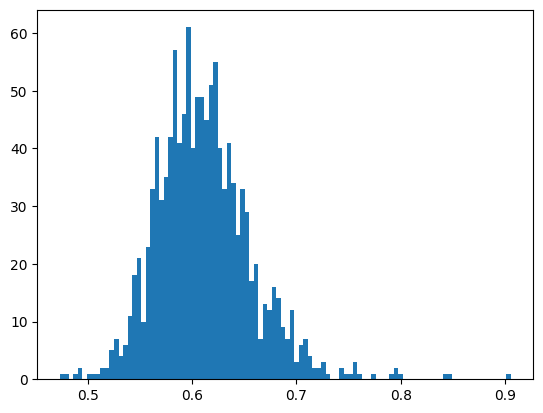

In [46]:
import matplotlib.pyplot as plt
plt.hist((sv_prob["prob"][:,msk_1,:].mean(1) / sv_prob["prob"][:,~msk_1,:].mean(1)).mean(1), bins=100)

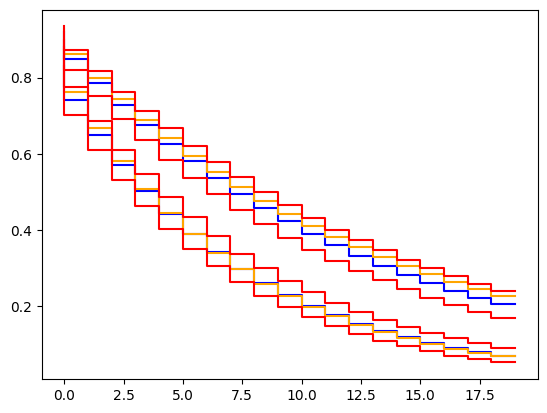

In [47]:

plt.step(range(20), sv_prob["sv"][:,1:500,:].mean(1).mean(0), color="blue")
plt.step(range(20), sv_prob["sv"][:,501:1000,:].mean(1).mean(0), color="blue")

plt.step(range(20), sv_true["sv_true"][(x_mat==1).flatten(), :].mean(0), color="orange")
plt.step(range(20), sv_true["sv_true"][(x_mat==0).flatten(), :].mean(0), color="orange")

plt.step(range(20), np.quantile(sv_prob["sv"][:,1:500,:].mean(1), [0.025], axis=0).flatten(), color="red")
plt.step(range(20), np.quantile(sv_prob["sv"][:,1:500,:].mean(1), [0.975], axis=0).flatten(), color="red")

plt.step(range(20), np.quantile(sv_prob["sv"][:,501:1000,:].mean(1), [0.025], axis=0).flatten(), color="red")
plt.step(range(20), np.quantile(sv_prob["sv"][:,501:1000,:].mean(1), [0.975], axis=0).flatten(), color="red")


In [ ]:
# BSM.bart_predict(X_pred=)